# DLE pas à pas : estimer l'erreur d'un forecaster sans vérité terrain

Ce notebook rejoue, en petit, le cœur du projet :

1. charger le forecaster figé de 2024 et ses prévisions ;
2. ajuster **NannyML DLE** sur la référence (sept.-déc. 2024) ;
3. estimer l'erreur de l'analysis (janv.-juin 2025) **sans lire les labels** ;
4. injecter un *covariate shift* puis un *concept drift* et voir lequel DLE détecte.

Prérequis : `make panel` (ou le panel versionné) puis `make e0`, qui met en cache le
modèle et ses prévisions.

In [1]:
import os
os.environ["NML_DISABLE_USAGE_LOGGING"] = "1"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from zonefleet import viz
from zonefleet.monitoring import estimate_performance, realized_performance
from zonefleet.pipeline import predictions
from zonefleet.scenarios import concept_drift, covariate_shift

viz.setup()
pred = predictions("congestion")
ref = pred[pred.period == "reference"]
an = pred[pred.period == "analysis"].reset_index(drop=True)
print(f"référence : {len(ref):,} lignes · analysis : {len(an):,} lignes")

référence : 175,680 lignes · analysis : 260,640 lignes


## 1. L'hétéroscédasticité que DLE va exploiter

DLE ne sert à rien si le modèle se trompe partout pareil. Regardons l'erreur relative
(MAE sur log1p) selon le niveau récent de la demande (`lag_168`) dans la référence.

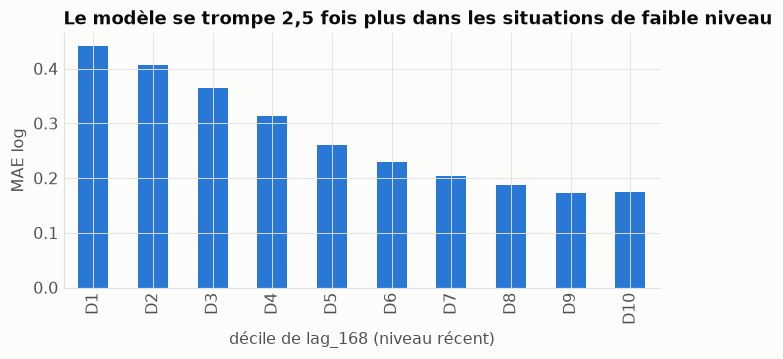

lag_168
D1     0.442
D2     0.407
D3     0.365
D4     0.314
D5     0.261
D6     0.229
D7     0.204
D8     0.187
D9     0.173
D10    0.175
dtype: float64

In [2]:
#| fig-alt: "Barres de l'erreur relative moyenne par décile de lag_168 dans la référence : environ 0,44 au premier décile, décroissante jusqu'à environ 0,17 aux deux derniers."
err = np.abs(np.log1p(ref["pickups"]) - np.log1p(ref["q50"]))
decile = pd.qcut(ref["lag_168"], 10, labels=[f"D{i}" for i in range(1, 11)])
by_decile = err.groupby(decile, observed=True).mean()
ax = by_decile.plot.bar(color=viz.BLUE, figsize=(7, 3))
ax.set_ylabel("MAE log")
ax.set_xlabel("décile de lag_168 (niveau récent)")
ax.set_title("Le modèle se trompe 2,5 fois plus dans les situations de faible niveau")
plt.show()
by_decile.round(3)

## 2. DLE sur l'analysis réelle

`estimate_performance` ajuste le nanny model sur la référence et estime l'analysis jour
par jour. Les labels de l'analysis ne lui sont **pas** transmis ; on les révèle
ensuite pour comparer.

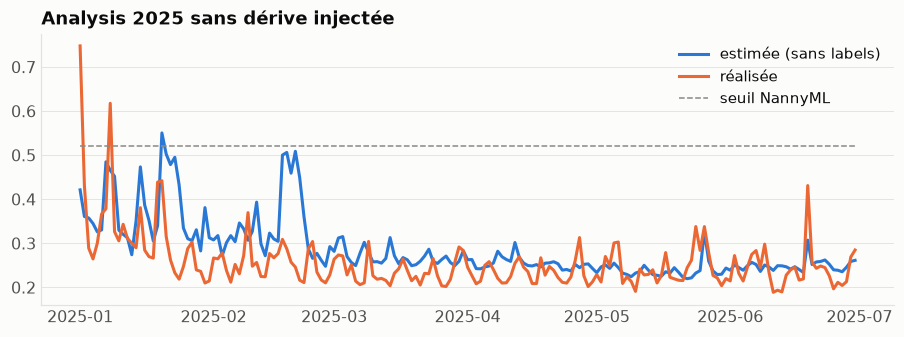

corrélation journalière : 0.48


In [3]:
#| fig-alt: "Courbes journalières de l'erreur estimée et réalisée sur l'analysis 2025 sans dérive, avec le seuil NannyML vers 0,52 : les deux courbes oscillent entre 0,2 et 0,5 ; l'estimée approche le seuil en janvier et fin février."
est = estimate_performance(ref, an, scale="log", metrics=("mae",))
real = realized_performance(an, scale="log").query("metric == 'mae_log'")
cmp = est.merge(real, on=["date", "metric"])
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(cmp["date"], cmp["estimated"], color=viz.BLUE, label="estimée (sans labels)")
ax.plot(cmp["date"], cmp["realized"], color=viz.ORANGE, label="réalisée")
ax.plot(cmp["date"], cmp["threshold"], color=viz.MUTED, ls="--", lw=1, label="seuil NannyML")
ax.legend(loc="upper right")
ax.set_title("Analysis 2025 sans dérive injectée")
plt.show()
print("corrélation journalière :", round(cmp["estimated"].corr(cmp["realized"]), 2))

## 3. Un covariate shift nuisible

À partir du 3 mars, chaque jour est rééchantillonné vers les situations de faible niveau
(poids exp(-z), z = `lag_168` standardisé). Chaque ligne reste une vraie ligne : la
relation X → y n'a pas changé, seule la distribution des entrées bouge.

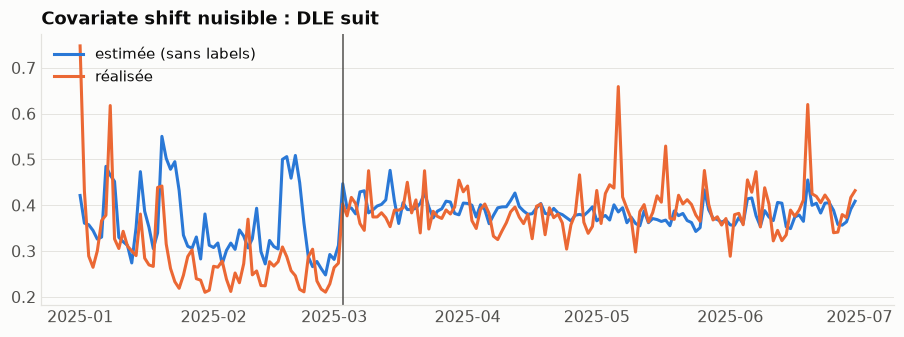

estimated    0.386
realized     0.391
dtype: float64

In [4]:
#| fig-alt: "Courbes journalières de l'erreur estimée et réalisée en 2025 avec un trait au 3 mars : après l'injection d'un covariate shift nuisible, les deux montent ensemble vers 0,4."
onset = pd.Timestamp("2025-03-03")
stats = (ref["lag_168"].mean(), ref["lag_168"].std())
an_cov = covariate_shift(an, onset, kappa=1.5, ref_stats=stats, seed=0)

def compare(df, title):
    e = estimate_performance(ref, df, scale="log", metrics=("mae",))
    r = realized_performance(df, scale="log").query("metric == 'mae_log'")
    c = e.merge(r, on=["date", "metric"])
    fig, ax = plt.subplots(figsize=(10, 3.2))
    ax.plot(c["date"], c["estimated"], color=viz.BLUE, label="estimée (sans labels)")
    ax.plot(c["date"], c["realized"], color=viz.ORANGE, label="réalisée")
    ax.axvline(onset, color=viz.INK2, lw=1)
    ax.legend(loc="upper left")
    ax.set_title(title)
    plt.show()
    post = c[c["date"] >= onset]
    return post[["estimated", "realized"]].mean().round(3)

compare(an_cov, "Covariate shift nuisible : DLE suit")

## 4. Un concept drift pur

Même date, mais cette fois la demande est divisée par deux **sans toucher aux
features** : le modèle et DLE voient exactement les mêmes entrées qu'avant.

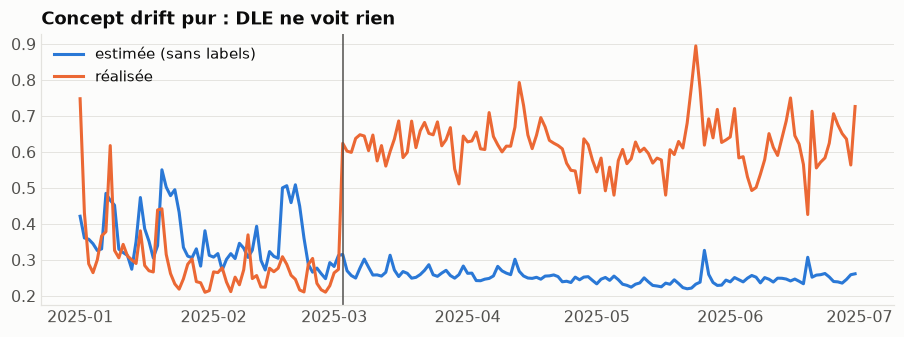

estimated    0.253
realized     0.621
dtype: float64

In [5]:
#| fig-alt: "Courbes journalières de l'erreur estimée et réalisée en 2025 avec un trait au 3 mars : après un concept drift pur, la réalisée saute vers 0,6 à 0,7 tandis que l'estimée reste vers 0,25."
an_con = concept_drift(an, onset, factor=0.5)
compare(an_con, "Concept drift pur : DLE ne voit rien")

## À retenir

- DLE transforme la fenêtre aveugle en fenêtre floue : il voit les dérives qui déplacent
  le modèle vers des régions où il se trompait déjà davantage.
- Il ne voit **pas** un changement de la relation X → y. Pour un forecaster à lags, tout
  choc brutal commence par là, jusqu'à ce que les lags l'absorbent.
- La mesure complète, sur 13 scénarios puis 240, est dans les pages
  [E3](../experiences/e3-frontiere.qmd) et [E4](../experiences/e4-backtest.qmd).